<a href="https://colab.research.google.com/github/enslern/The-AI-engineer-course-2026-Complete-AI-bootcamp/blob/main/langgraph_long_term_memory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Short-Term Memory with the InMemorySaver Class

### Set the OpenAI API Key as an Environment Variable

In [1]:
!pip install langchain==0.3.25
!pip install langgraph==0.4.8
!pip install langchain-groq
!pip install langgraph-checkpoint-sqlite
!pip install grandalf==0.8

  Using cached langchain_core-0.3.86-py3-none-any.whl.metadata (3.2 kB)
Using cached langchain_core-0.3.86-py3-none-any.whl (461 kB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-groq 1.1.3 requires langchain-core<2.0.0,>=1.4.0, but you have langchain-core 0.3.86 which is incompatible.
langgraph-prebuilt 1.1.0 requires langchain-core>=1.3.1, but you have langchain-core 0.3.86 which is incompatible.
langgraph-sdk 0.4.5 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.3.86 which is incompatible.
  Using cached langchain_core-1.6.10-py3-none-any.whl.metadata (4.8 kB)
Using cached langchain_core-1.6.10-py3-none-any.whl (573 kB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain 0.3.25 requires langchain-co

In [2]:
import os
import sys
import importlib.util

target_path = "/content/drive/MyDrive/Colab Notebooks/resources"
config_file_path = os.path.join(target_path, "config.py")

if os.path.exists(config_file_path):
    # Load the config module directly from its absolute file path
    spec = importlib.util.spec_from_file_location("config", config_file_path)
    config = importlib.util.module_from_spec(spec)
    sys.modules["config"] = config
    spec.loader.exec_module(config)

    # Set the environment variable
    os.environ["GROQ_API_KEY"] = config.GROQ_API_KEY
    print("[SUCCESS] Successfully imported config and set GROQ_API_KEY!")
else:
    print(f"[ERROR] Could not locate 'config.py' at {config_file_path}")



[SUCCESS] Successfully imported config and set GROQ_API_KEY!


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Import Relevant Classes and Functions

In [5]:
from langgraph.graph import START, END, StateGraph, MessagesState
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage, BaseMessage, RemoveMessage
from langgraph.checkpoint.memory import InMemorySaver
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

### Define the State

In [6]:
class State(MessagesState):
    summary: str

### Define the Nodes

In [68]:
chat = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    max_tokens=500
)

In [80]:
def ask_question(state: State) -> dict:
    print("\n-------> ENTERING ask_question:")

    question = input("What is your question? ")

    return {
        "messages": [HumanMessage(content=question)]
    }

In [81]:
def chatbot(state: State) -> State:

    print(f"\n-------> ENTERING chatbot:")

    system_message = f'''
    Here's a quick summary of what's been discussed so far:
    {state.get("summary", "")}

    Keep this in mind as you answer the next question.
    '''

    response = chat.invoke([SystemMessage(system_message)] + state["messages"])
    response.pretty_print()

    return State(messages = [response])

In [82]:
def summarize_messages(state: State) -> State:
    print(f"\n-------> ENTERING summarize_messages:")

    new_conversation = ""
    for i in state["messages"]:
        new_conversation += f"{i.type}: {i.content}\n\n"

    summary_instructions = f'''
Update the ongoing summary by incorporating the new lines of conversation below.
Build upon the previous summary rather than repeating it,
so that the result reflects the most recent context and developments.
Respond only with the summary.

Previous Summary:
{state.get("summary", "")}

New Conversation:
{new_conversation}
'''

    print(summary_instructions)

    summary = chat.invoke([HumanMessage(summary_instructions)])

    remove_messages = [RemoveMessage(id = i.id) for i in state["messages"][:]]


    return {
        "messages": remove_messages,
        "summary": summary.content
    }

### Define the Graph

In [83]:
graph = StateGraph(State)

In [84]:
graph.add_node("ask_question", ask_question)
graph.add_node("chatbot", chatbot)
graph.add_node("summarize_messages", summarize_messages)

graph.add_edge(START, "ask_question")
graph.add_edge("ask_question", "chatbot")
graph.add_edge("chatbot", "summarize_messages")
graph.add_edge("summarize_messages", END)

In [85]:
db_path="/content/drive/MyDrive/Colab Notebooks/resources/langgraph.db"
con=sqlite3.connect(database=db_path,check_same_thread=False)

In [86]:
checkpointer=SqliteSaver(con)

In [87]:

graph_compiled = graph.compile(checkpointer)

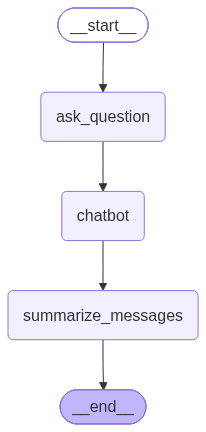

In [88]:
graph_compiled

In [89]:
config1 = {"configurable": {"thread_id": "1"}}
config2 = {"configurable": {"thread_id": "2"}}

In [ ]:
graph_compiled.invoke({"messages": []}, config1)